/var/folders/p8/clmlgd195158bhn2rw36wbg40000gn/T/ipykernel_7024/4164945271.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dia_semana"] = df["first_contact_date"].dt.dayofweek


Train: (3343, 22) 0.1191 | Test: (2655, 22) 0.1055
AUC-PR: 0.1914 (línea base aleatoria = 0.1055)
AUC-ROC: 0.6747
Precision: 0.187 | Recall: 0.596 | F1: 0.285


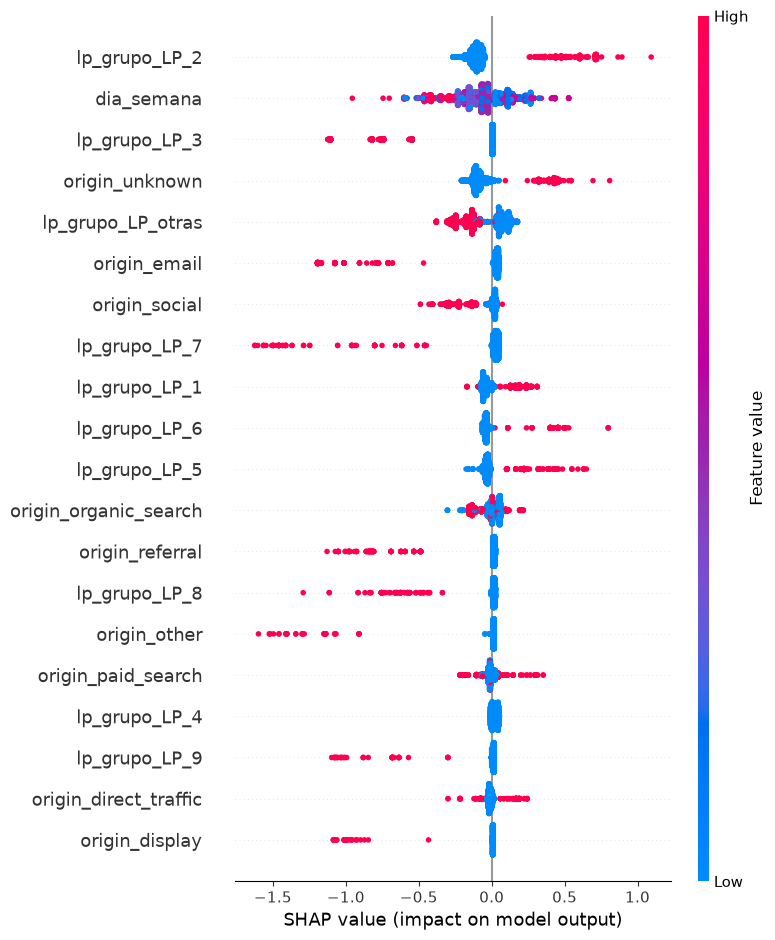

lp_grupo_LP_2            0.159035
dia_semana               0.155830
lp_grupo_LP_3            0.148644
origin_unknown           0.136899
lp_grupo_LP_otras        0.116983
origin_email             0.091554
origin_social            0.065088
lp_grupo_LP_7            0.056767
lp_grupo_LP_1            0.055984
lp_grupo_LP_6            0.054855
lp_grupo_LP_5            0.047985
origin_organic_search    0.047341
dtype: float32


In [1]:
import pandas as pd, numpy as np
import xgboost as xgb
import shap
import matplotlib.pyplot as plt
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_recall_fscore_support)

# 1. Cargar datos procesados
df = pd.read_csv("../data/leads_procesados.csv",
                 parse_dates=["first_contact_date", "won_date"])
df["dia_semana"] = df["first_contact_date"].dt.dayofweek

# 2. Variables y objetivo (solo info disponible al momento del lead: sin fuga)
y = df["conv_90"]
X = pd.get_dummies(df[["origin", "lp_grupo", "dia_semana"]],
                   columns=["origin", "lp_grupo"]).astype(float)

# 3. Split temporal: ene-mar entrena, abr-may prueba
corte = pd.Timestamp("2018-04-01")
tr = df["first_contact_date"] < corte
X_train, y_train = X[tr], y[tr]
X_test, y_test = X[~tr], y[~tr]
print("Train:", X_train.shape, y_train.mean().round(4),
      "| Test:", X_test.shape, y_test.mean().round(4))

# 4. Modelo (scale_pos_weight compensa el desbalance)
spw = (y_train == 0).sum() / (y_train == 1).sum()
model = xgb.XGBClassifier(
    n_estimators=300, max_depth=3, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=spw, eval_metric="aucpr", random_state=42)
model.fit(X_train, y_train)

# 5. Evaluación
proba = model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
p, r, f1, _ = precision_recall_fscore_support(y_test, pred, average="binary")
print(f"AUC-PR: {average_precision_score(y_test, proba):.4f} "
      f"(línea base aleatoria = {y_test.mean():.4f})")
print(f"AUC-ROC: {roc_auc_score(y_test, proba):.4f}")
print(f"Precision: {p:.3f} | Recall: {r:.3f} | F1: {f1:.3f}")

# 6. SHAP: qué variables explican la conversión
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(X_test)
shap.summary_plot(sv, X_test, show=False)
plt.tight_layout()
plt.savefig("../docs/shap_summary.png", dpi=200)
plt.show()

imp = pd.Series(np.abs(sv).mean(axis=0), index=X_test.columns).sort_values(ascending=False)
print(imp.head(12))

In [2]:
from sklearn.linear_model import LogisticRegression

# 1. ¿La conversión por día de la semana es estable entre train y test?
print("TRAIN:\n", df[tr].groupby("dia_semana")["conv_90"].agg(leads="count", tasa="mean").round(3))
print("TEST:\n", df[~tr].groupby("dia_semana")["conv_90"].agg(leads="count", tasa="mean").round(3))

# 2. Lift en el 10% de leads con mayor probabilidad
def lift_top(y, p, q=0.1):
    k = int(len(y) * q)
    idx = np.argsort(p)[::-1][:k]
    return y.values[idx].mean() / y.mean()

# 3. Comparar: con y sin dia_semana, y contra regresión logística
def xgb_modelo():
    return xgb.XGBClassifier(
        n_estimators=200, max_depth=3, learning_rate=0.05, min_child_weight=5,
        subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
        eval_metric="aucpr", random_state=42)

cols_todas = list(X.columns)
cols_sin_dia = [c for c in cols_todas if c != "dia_semana"]

resultados = {}
for nombre, cols, mod in [
    ("XGB con dia_semana", cols_todas, xgb_modelo()),
    ("XGB sin dia_semana", cols_sin_dia, xgb_modelo()),
    ("Regresion logistica", cols_sin_dia,
     LogisticRegression(max_iter=1000, class_weight="balanced")),
]:
    mod.fit(X_train[cols], y_train)
    p = mod.predict_proba(X_test[cols])[:, 1]
    resultados[nombre] = {
        "AUC-PR": average_precision_score(y_test, p),
        "AUC-ROC": roc_auc_score(y_test, p),
        "Lift top 10%": lift_top(y_test, p),
    }
print(pd.DataFrame(resultados).T.round(4))

TRAIN:
             leads   tasa
dia_semana              
0             630  0.116
1             583  0.136
2             635  0.109
3             563  0.112
4             481  0.143
5             224  0.103
6             227  0.097
TEST:
             leads   tasa
dia_semana              
0             518  0.095
1             480  0.115
2             514  0.099
3             458  0.114
4             344  0.140
5             171  0.064
6             170  0.082
                     AUC-PR  AUC-ROC  Lift top 10%
XGB con dia_semana   0.1932   0.6825        2.1469
XGB sin dia_semana   0.1816   0.6847        1.9680
Regresion logistica  0.1828   0.6855        2.0753


In [3]:
from scipy.stats import chi2_contingency

# 1. ¿Hay relación entre día de la semana y conversión? (todo el periodo)
tab = pd.crosstab(df["dia_semana"], df["conv_90"])
chi2, pval, _, _ = chi2_contingency(tab)
print(f"Día de la semana: chi2 = {chi2:.2f} | p-value = {pval:.4f}")

# 2. Entrenar los tres modelos y guardar probabilidades
probas = {}
for nombre, cols, mod in [
    ("XGB con dia", cols_todas, xgb_modelo()),
    ("XGB sin dia", cols_sin_dia, xgb_modelo()),
    ("Logistica", cols_sin_dia, LogisticRegression(max_iter=1000, class_weight="balanced")),
]:
    mod.fit(X_train[cols], y_train)
    probas[nombre] = mod.predict_proba(X_test[cols])[:, 1]

# 3. Bootstrap pareado sobre el test (1000 remuestreos)
rng = np.random.default_rng(42)
yt = y_test.values
n = len(yt)
res = {k: [] for k in probas}
dif_dia, dif_lr = [], []

for _ in range(1000):
    i = rng.integers(0, n, n)
    if yt[i].sum() == 0:
        continue
    ap = {k: average_precision_score(yt[i], p[i]) for k, p in probas.items()}
    for k in probas:
        res[k].append(ap[k])
    dif_dia.append(ap["XGB con dia"] - ap["XGB sin dia"])
    dif_lr.append(ap["XGB con dia"] - ap["Logistica"])

for k, v in res.items():
    print(f"AUC-PR {k}: {np.mean(v):.4f}  IC95% [{np.percentile(v, 2.5):.4f}, {np.percentile(v, 97.5):.4f}]")

print(f"\nXGB con dia - sin dia:   {np.mean(dif_dia):+.4f}  IC95% [{np.percentile(dif_dia, 2.5):+.4f}, {np.percentile(dif_dia, 97.5):+.4f}]")
print(f"XGB con dia - Logistica: {np.mean(dif_lr):+.4f}  IC95% [{np.percentile(dif_lr, 2.5):+.4f}, {np.percentile(dif_lr, 97.5):+.4f}]")

Día de la semana: chi2 = 14.83 | p-value = 0.0216
AUC-PR XGB con dia: 0.1960  IC95% [0.1627, 0.2322]
AUC-PR XGB sin dia: 0.1829  IC95% [0.1550, 0.2110]
AUC-PR Logistica: 0.1846  IC95% [0.1561, 0.2149]

XGB con dia - sin dia:   +0.0131  IC95% [-0.0035, +0.0339]
XGB con dia - Logistica: +0.0114  IC95% [-0.0081, +0.0337]


In [5]:
import json

spw_total = (y == 0).sum() / (y == 1).sum()
final = xgb.XGBClassifier(
    n_estimators=200, max_depth=3, learning_rate=0.05, min_child_weight=5,
    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw_total,
    eval_metric="aucpr", random_state=42)
final.fit(X[cols_todas], y)

final.save_model("../app/modelo_xgb.json")
with open("../app/columnas_modelo.json", "w") as f:
    json.dump(cols_todas, f)